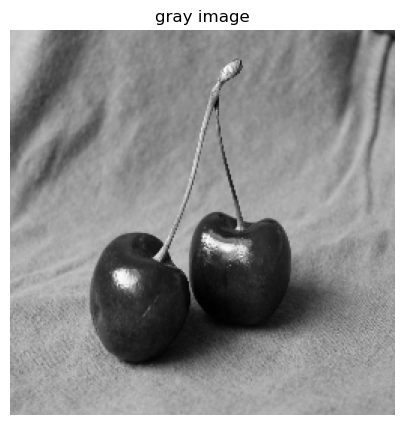

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv
image_path="p1.jpg"
image_y=cv.imread(image_path)
if image_y is None:
    print("there is no image")
else:
    image_gray=cv.cvtColor(image_y,cv.COLOR_BGR2GRAY)
    image_resized=cv.resize(image_gray,(256,256),interpolation=cv.INTER_LINEAR) 
plt.figure(figsize=(5,5))
plt.imshow(image_resized,cmap="gray")
plt.title("gray image")
plt.axis("off")
plt.show()    

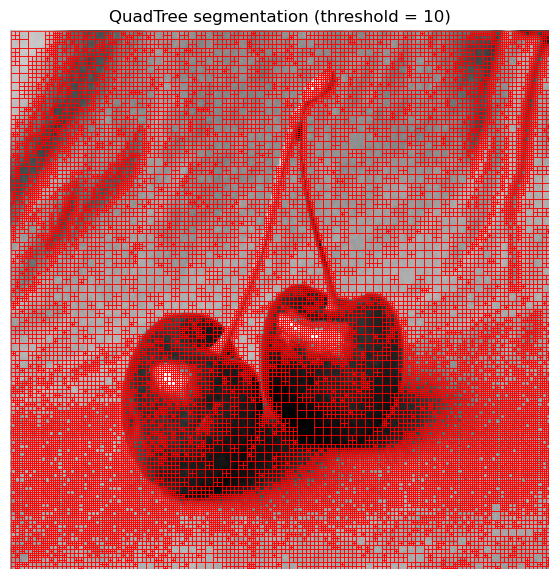

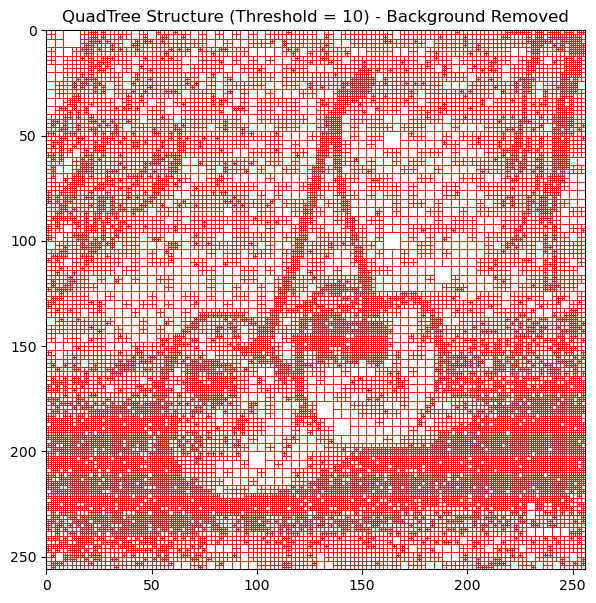

In [8]:
import matplotlib.patches as patches
class QuadTreeNode:
    def __init__(self,x,y,size):
        self.x=x
        self.y=y
        self.size=size
        self.children=[]
        self.is_leaf=True
def is_homogeneous(image,x,y,size,threshold):
    block=image[y:y+size,x:x+size]
    min_val=np.min(block)
    max_val=np.max(block)
    return (max_val-min_val)<=threshold
def build_quadtree(image,x,y,size,threshold):
    node=QuadTreeNode(x,y,size)
    if is_homogeneous(image,x,y,size,threshold) or size<=1:
        node.is_leaf=True
        return node
    node.is_leaf=False
    half_size=size//2
    node.children.append(build_quadtree(image,x,y,half_size,threshold))
    node.children.append(build_quadtree(image,x+half_size,y,half_size,threshold))
    node.children.append(build_quadtree(image,x,y+half_size,half_size,threshold))
    node.children.append(build_quadtree(image,x+half_size,y+half_size,half_size,threshold))
    return node
def draw_quadtree(node,ax):
    if node.is_leaf:
        rect=patches.Rectangle((node.x,node.y),node.size,node.size,linewidth=0.5,edgecolor='red',facecolor='none')
        ax.add_patch(rect)
    else:
        for child in node.children:
            draw_quadtree(child,ax)
threshold_value=10
root_node=build_quadtree(image_resized,0,0,256,threshold_value)
fig,ax=plt.subplots(figsize=(7,7))
ax.imshow(image_resized,cmap="gray")
draw_quadtree(root_node,ax)
plt.title(f"QuadTree segmentation (threshold = {threshold_value})")
plt.axis('off')
plt.show()            

threshold_value = 10
root_node = build_quadtree(image_resized, 0, 0, 256, threshold_value)
fig, ax = plt.subplots(figsize=(7, 7))
ax.set_xlim(0, 256)
ax.set_ylim(256, 0) 
draw_quadtree(root_node, ax)
plt.title(f"QuadTree Structure (Threshold = {threshold_value}) - Background Removed")
plt.axis('on')
plt.grid(False) 
plt.gca().set_aspect('equal', adjustable='box') 
plt.show()

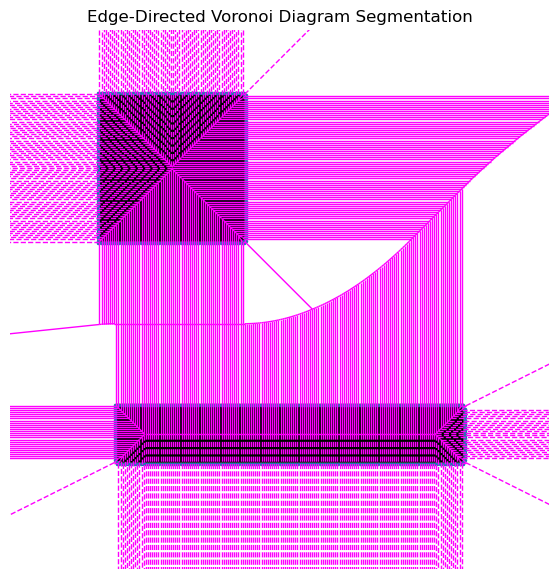

In [4]:
from scipy.spatial import Voronoi, voronoi_plot_2d
edges = cv.Canny(image_resized, 100, 200)
y_indices, x_indices = np.where(edges > 0)
edge_points = np.column_stack((x_indices, y_indices))

num_points_to_use = 3000
if len(edge_points) > num_points_to_use:
    indices = np.random.choice(len(edge_points), num_points_to_use, replace=False)
    points = edge_points[indices]
else:
    points = edge_points

vor = Voronoi(points)

fig, ax = plt.subplots(figsize=(7, 7))

ax.imshow(image_resized, cmap='gray')
voronoi_plot_2d(vor, ax=ax, show_points=True, show_vertices=False, 
                line_colors='magenta', line_width=1.0, point_size=3)

ax.set_xlim(0, 256)
ax.set_ylim(256, 0) 
plt.title("Edge-Directed Voronoi Diagram Segmentation")
plt.axis('off')
plt.show()

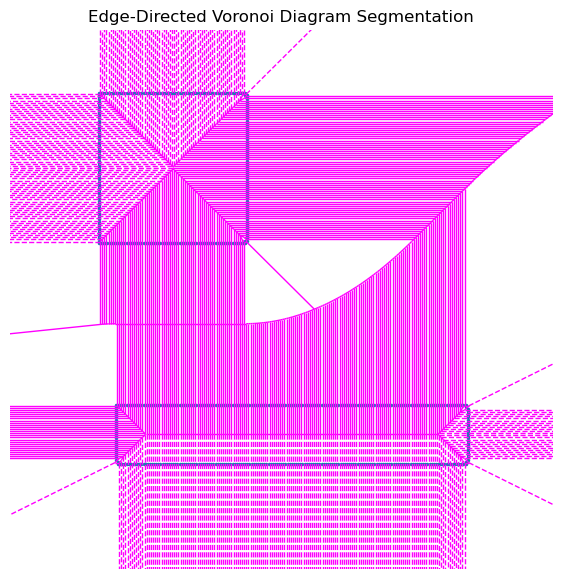

In [5]:
edges = cv.Canny(image_resized, 100, 200)
y_indices, x_indices = np.where(edges > 0)
edge_points = np.column_stack((x_indices, y_indices))

num_points_to_use = 3000
if len(edge_points) > num_points_to_use:
    indices = np.random.choice(len(edge_points), num_points_to_use, replace=False)
    points = edge_points[indices]
else:
    points = edge_points

vor = Voronoi(points)

fig, ax = plt.subplots(figsize=(7, 7))


voronoi_plot_2d(vor, ax=ax, show_points=True, show_vertices=False, 
                line_colors='magenta', line_width=1.0, point_size=3)

ax.set_xlim(0, 256)
ax.set_ylim(256, 0) 
plt.title("Edge-Directed Voronoi Diagram Segmentation")
plt.axis('off')
plt.show()

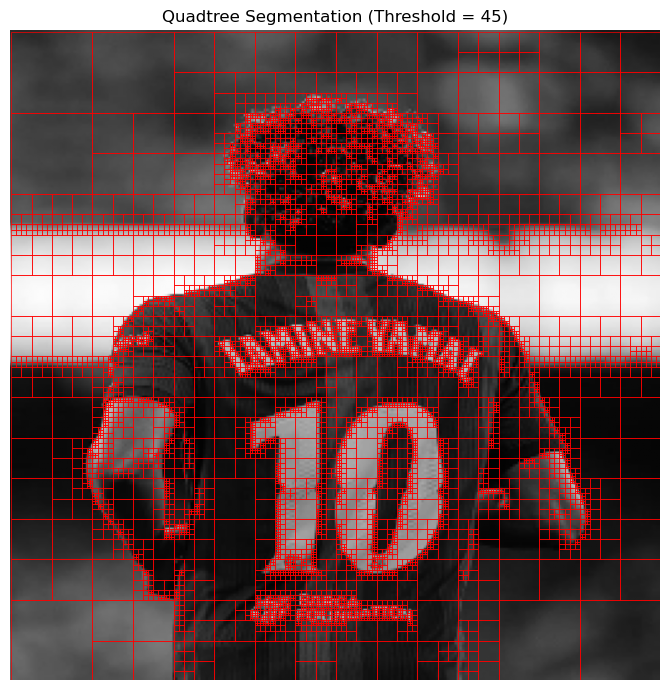

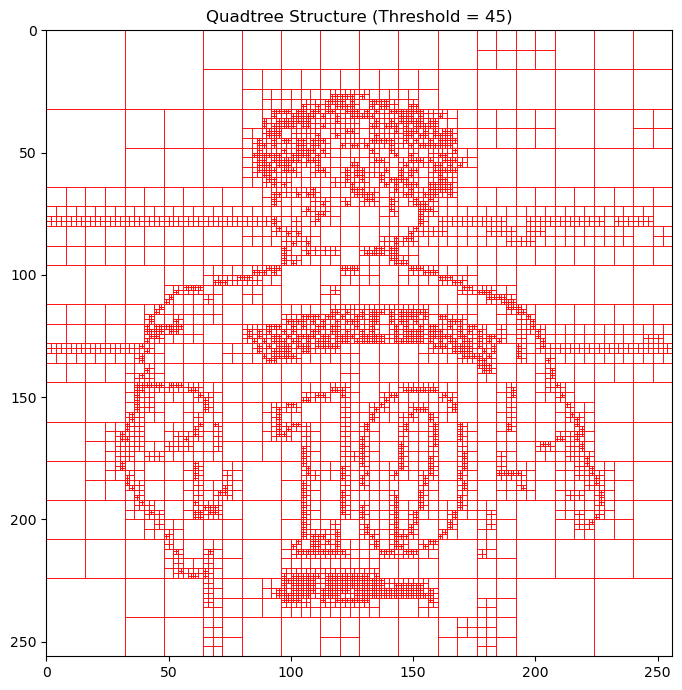

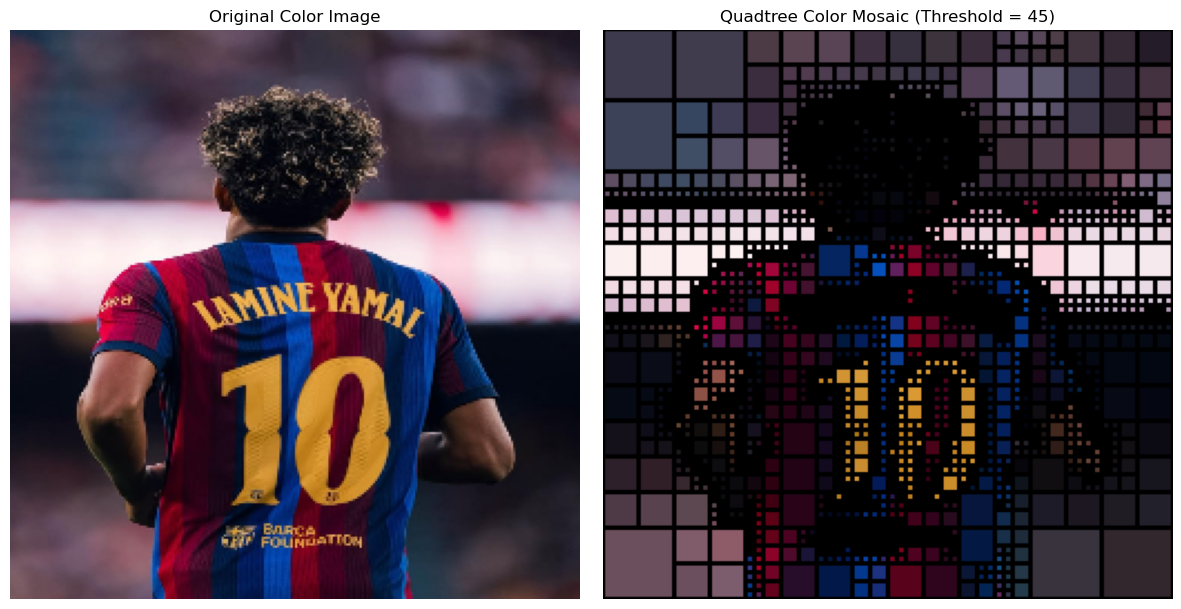

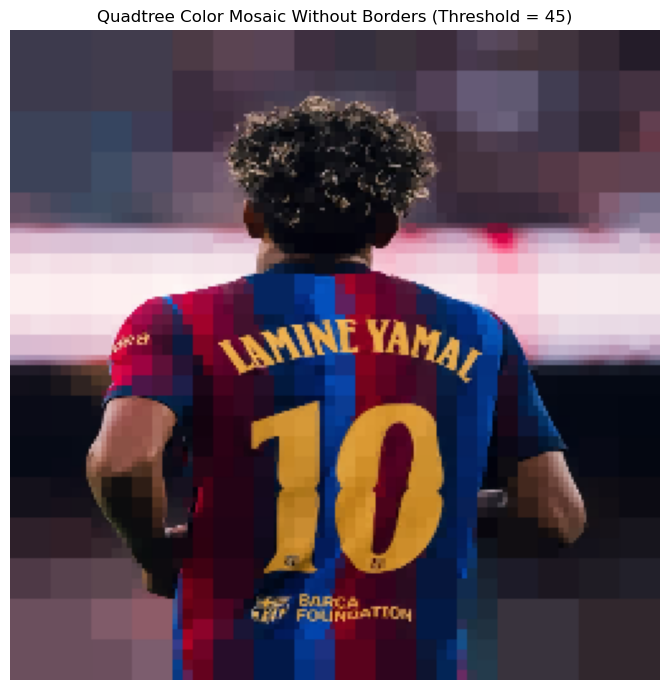

In [5]:

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import cv2 as cv

# ==========================================
# 1. Load and prepare the image
# ==========================================

image_path = "p0.jpg"

image_y = cv.imread(image_path)

if image_y is None:
    print("There is no image. Check the image path.")

else:
    # Original color image
    image_color = cv.resize(
        image_y,
        (256, 256),
        interpolation=cv.INTER_LINEAR
    )

    # Grayscale image used for Quadtree segmentation
    image_gray = cv.cvtColor(
        image_color,
        cv.COLOR_BGR2GRAY
    )

    image_resized = image_gray.copy()


    # ==========================================
    # 2. Quadtree Node
    # ==========================================

    class QuadTreeNode:
        def __init__(self, x, y, size):
            self.x = x
            self.y = y
            self.size = size
            self.children = []
            self.is_leaf = True


    # ==========================================
    # 3. Check block homogeneity
    # ==========================================

    def is_homogeneous(image, x, y, size, threshold):
        block = image[y:y + size, x:x + size]

        min_val = np.min(block)
        max_val = np.max(block)

        return (max_val - min_val) <= threshold


    # ==========================================
    # 4. Build the Quadtree
    # ==========================================

    def build_quadtree(image, x, y, size, threshold):
        node = QuadTreeNode(x, y, size)

        if (
            is_homogeneous(image, x, y, size, threshold)
            or size <= 1
        ):
            node.is_leaf = True
            return node

        node.is_leaf = False
        half_size = size // 2

        # Top-left
        node.children.append(
            build_quadtree(
                image, x, y, half_size, threshold
            )
        )

        # Top-right
        node.children.append(
            build_quadtree(
                image, x + half_size, y, half_size, threshold
            )
        )

        # Bottom-left
        node.children.append(
            build_quadtree(
                image, x, y + half_size, half_size, threshold
            )
        )

        # Bottom-right
        node.children.append(
            build_quadtree(
                image,
                x + half_size,
                y + half_size,
                half_size,
                threshold
            )
        )

        return node


    # ==========================================
    # 5. Draw Quadtree over the image
    # ==========================================

    def draw_quadtree(node, ax):
        if node.is_leaf:
            rect = patches.Rectangle(
                (node.x, node.y),
                node.size,
                node.size,
                linewidth=0.5,
                edgecolor="red",
                facecolor="none"
            )

            ax.add_patch(rect)

        else:
            for child in node.children:
                draw_quadtree(child, ax)


    # ==========================================
    # 6. Paint each leaf with its average color
    # ==========================================

    def paint_quadtree(
        node,
        original_image,
        result_image,
        show_borders=True
    ):
        if node.is_leaf:
            x = node.x
            y = node.y
            size = node.size

            # Extract the corresponding color block
            block = original_image[
                y:y + size,
                x:x + size
            ]

            # Calculate average color (BGR)
            mean_color = np.mean(
                block,
                axis=(0, 1)
            ).astype(np.uint8)

            # Fill the block with its average color
            result_image[
                y:y + size,
                x:x + size
            ] = mean_color

            # Optional black borders
            if show_borders:
                cv.rectangle(
                    result_image,
                    (x, y),
                    (x + size - 1, y + size - 1),
                    (0, 0, 0),
                    1
                )

        else:
            for child in node.children:
                paint_quadtree(
                    child,
                    original_image,
                    result_image,
                    show_borders
                )


    # ==========================================
    # 7. Run Quadtree
    # ==========================================

    threshold_value = 45

    root_node = build_quadtree(
        image_resized,
        0,
        0,
        256,
        threshold_value
    )


    # ==========================================
    # 8. Display 1: Quadtree over the original image
    # ==========================================

    fig, ax = plt.subplots(figsize=(7, 7))

    ax.imshow(image_resized, cmap="gray")
    draw_quadtree(root_node, ax)

    plt.title(
        f"Quadtree Segmentation (Threshold = {threshold_value})"
    )

    plt.axis("off")
    plt.tight_layout()
    plt.show()


    # ==========================================
    # 9. Display 2: Quadtree structure only
    # ==========================================

    fig, ax = plt.subplots(figsize=(7, 7))

    ax.set_xlim(0, 256)
    ax.set_ylim(256, 0)

    draw_quadtree(root_node, ax)

    plt.title(
        f"Quadtree Structure (Threshold = {threshold_value})"
    )

    ax.set_aspect("equal", adjustable="box")
    ax.grid(False)

    plt.tight_layout()
    plt.show()


    # ==========================================
    # 10. Display 3: Color mosaic
    # ==========================================

    result_image = image_color.copy()

    paint_quadtree(
        root_node,
        image_color,
        result_image,
        show_borders=True
    )

    # OpenCV uses BGR; Matplotlib uses RGB
    original_rgb = cv.cvtColor(
        image_color,
        cv.COLOR_BGR2RGB
    )

    result_rgb = cv.cvtColor(
        result_image,
        cv.COLOR_BGR2RGB
    )

    fig, ax = plt.subplots(1, 2, figsize=(12, 6))

    ax[0].imshow(original_rgb)
    ax[0].set_title("Original Color Image")
    ax[0].axis("off")

    ax[1].imshow(result_rgb)
    ax[1].set_title(
        f"Quadtree Color Mosaic (Threshold = {threshold_value})"
    )
    ax[1].axis("off")

    plt.tight_layout()
    plt.show()


    # ==========================================
    # 11. Display 4: Color mosaic without borders
    # ==========================================

    result_no_borders = image_color.copy()

    paint_quadtree(
        root_node,
        image_color,
        result_no_borders,
        show_borders=False
    )

    result_no_borders_rgb = cv.cvtColor(
        result_no_borders,
        cv.COLOR_BGR2RGB
    )

    plt.figure(figsize=(7, 7))

    plt.imshow(result_no_borders_rgb)

    plt.title(
        f"Quadtree Color Mosaic Without Borders "
        f"(Threshold = {threshold_value})"
    )

    plt.axis("off")
    plt.tight_layout()
    plt.show()


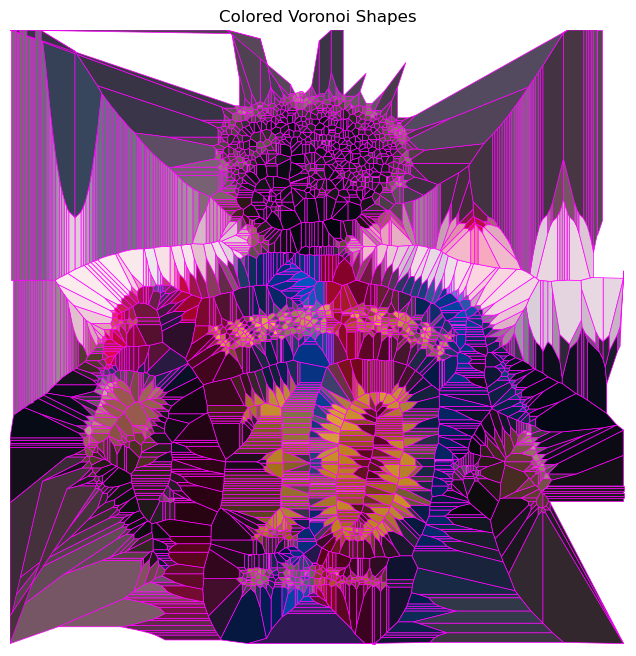

In [8]:

import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv
from scipy.spatial import Voronoi
from matplotlib.patches import Polygon

# 1. Read the image
image_path = "p0.jpg"
image_color = cv.imread(image_path)

if image_color is None:
    print("There is no image")

else:
    # 2. Resize the image
    image_color = cv.resize(image_color, (256, 256))

    # 3. Convert to grayscale
    image_gray = cv.cvtColor(image_color, cv.COLOR_BGR2GRAY)

    # 4. Detect edges
    edges = cv.Canny(image_gray, 100, 200)

    # 5. Extract edge points
    y_indices, x_indices = np.where(edges > 0)
    edge_points = np.column_stack((x_indices, y_indices))

    # 6. Select points
    num_points_to_use = 3000

    if len(edge_points) > num_points_to_use:
        indices = np.random.choice(
            len(edge_points),
            num_points_to_use,
            replace=False
        )
        points = edge_points[indices]
    else:
        points = edge_points

    # 7. Create Voronoi diagram
    if len(points) >= 4:
        vor = Voronoi(points)

        # 8. Create a blank white background
        fig, ax = plt.subplots(figsize=(8, 8))
        ax.set_facecolor("white")

        # 9. Color the Voronoi shapes only
        for point_region in vor.point_region:
            region = vor.regions[point_region]

            # Ignore empty and infinite regions
            if not region or -1 in region:
                continue

            polygon = vor.vertices[region].copy()

            # Keep shapes inside the image boundaries
            polygon[:, 0] = np.clip(polygon[:, 0], 0, 255)
            polygon[:, 1] = np.clip(polygon[:, 1], 0, 255)

            # Create a mask for this shape
            mask = np.zeros((256, 256), dtype=np.uint8)
            polygon_int = np.round(polygon).astype(np.int32)
            cv.fillPoly(mask, [polygon_int], 255)

            # Calculate the average color of the original image
            mean_color = cv.mean(image_color, mask=mask)[:3]

            # Convert BGR to RGB
            color_rgb = tuple(
                channel / 255 for channel in mean_color[::-1]
            )

            # Draw only the colored shape
            patch = Polygon(
                polygon,
                closed=True,
                facecolor=color_rgb,
                edgecolor='magenta',
                linewidth=0.5
            )
            ax.add_patch(patch)

        # 10. Display shapes without the original image
        ax.set_xlim(0, 256)
        ax.set_ylim(256, 0)
        ax.set_aspect('equal')
        ax.axis('off')
        plt.title("Colored Voronoi Shapes")
        plt.show()

    else:
        print("Not enough edge points to create a Voronoi diagram.")


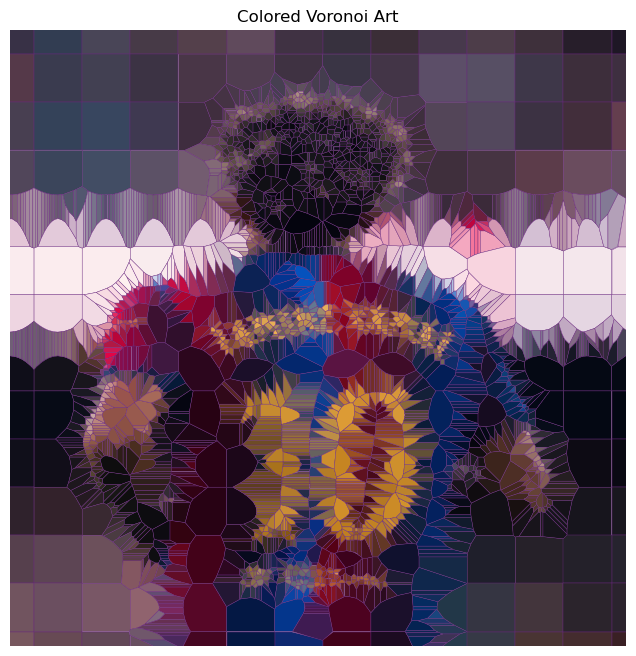

In [10]:

import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv
from scipy.spatial import Voronoi
from matplotlib.patches import Polygon

# 1. Read the original image
image_path = "p0.jpg"
image_color = cv.imread(image_path)

if image_color is None:
    print("There is no image")

else:
    # 2. Resize the image
    image_color = cv.resize(image_color, (256, 256))
    image_gray = cv.cvtColor(image_color, cv.COLOR_BGR2GRAY)

    # 3. Detect edges
    edges = cv.Canny(image_gray, 100, 200)

    # 4. Extract points from edges
    y_indices, x_indices = np.where(edges > 0)
    edge_points = np.column_stack((x_indices, y_indices))

    # 5. Select edge points
    num_points_to_use = 3000

    if len(edge_points) > num_points_to_use:
        indices = np.random.choice(
            len(edge_points),
            num_points_to_use,
            replace=False
        )
        points = edge_points[indices]
    else:
        points = edge_points

    # 6. Add regularly spaced points, including outside the image
    grid_x, grid_y = np.meshgrid(
        np.arange(-40, 300, 20),
        np.arange(-40, 300, 20)
    )

    grid_points = np.column_stack((
        grid_x.ravel(),
        grid_y.ravel()
    ))

    # Combine edge points and grid points
    points = np.vstack((points, grid_points))
    points = np.unique(points, axis=0)

    # 7. Create the Voronoi diagram
    if len(points) >= 4:
        vor = Voronoi(points)

        # 8. Create a blank white background
        fig, ax = plt.subplots(figsize=(8, 8))
        ax.set_facecolor("white")

        # 9. Color the Voronoi regions
        for point_region in vor.point_region:
            region = vor.regions[point_region]

            # Ignore empty and infinite regions
            if not region or -1 in region:
                continue

            polygon = vor.vertices[region]

            # Create a mask for the polygon
            mask = np.zeros((256, 256), dtype=np.uint8)
            polygon_int = np.round(polygon).astype(np.int32)

            cv.fillPoly(mask, [polygon_int], 255)

            # Ignore polygons outside the image
            if cv.countNonZero(mask) == 0:
                continue

            # Calculate the average color of the region
            mean_color = cv.mean(image_color, mask=mask)[:3]

            # Convert BGR to RGB
            color_rgb = tuple(
                channel / 255 for channel in mean_color[::-1]
            )

            # Draw the colored polygon
            patch = Polygon(
                polygon,
                closed=True,
                facecolor=color_rgb,
                edgecolor='#6A287E',
                linewidth=0.3
            )

            ax.add_patch(patch)

        # 10. Display the final result without the original image
        ax.set_xlim(0, 256)
        ax.set_ylim(256, 0)
        ax.set_aspect('equal')
        ax.axis('off')

        plt.title("Colored Voronoi Art")
        plt.show()

    else:
        print("Not enough points to create Voronoi.")


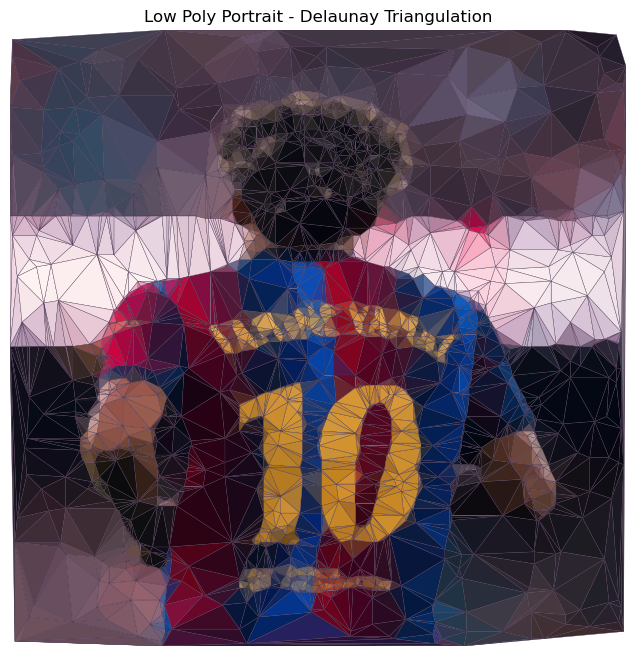

In [11]:

import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv
from scipy.spatial import Delaunay
from matplotlib.patches import Polygon

# 1. Read the image
image_path = "p0.jpg"
image_color = cv.imread(image_path)

if image_color is None:
    print("There is no image")

else:
    # 2. Resize the image
    image_color = cv.resize(image_color, (256, 256))
    image_gray = cv.cvtColor(image_color, cv.COLOR_BGR2GRAY)

    # 3. Detect edges
    edges = cv.Canny(image_gray, 100, 200)

    # 4. Extract edge points
    y_indices, x_indices = np.where(edges > 0)
    edge_points = np.column_stack((x_indices, y_indices))

    # 5. Select edge points
    num_points_to_use = 1500

    if len(edge_points) > num_points_to_use:
        indices = np.random.choice(
            len(edge_points),
            num_points_to_use,
            replace=False
        )
        points = edge_points[indices]
    else:
        points = edge_points

    # 6. Add randomly distributed points
    np.random.seed(42)

    random_points = np.column_stack((
        np.random.randint(0, 256, 500),
        np.random.randint(0, 256, 500)
    ))

    points = np.vstack((points, random_points))
    points = np.unique(points, axis=0)

    # 7. Create Delaunay triangles
    if len(points) >= 3:
        triangulation = Delaunay(points)

        # 8. Create a white background
        fig, ax = plt.subplots(figsize=(8, 8))
        ax.set_facecolor("white")

        # 9. Color each triangle
        for triangle_indices in triangulation.simplices:
            triangle = points[triangle_indices]

            # Create a mask for the triangle
            mask = np.zeros((256, 256), dtype=np.uint8)
            triangle_int = triangle.astype(np.int32)

            cv.fillPoly(mask, [triangle_int], 255)

            if cv.countNonZero(mask) == 0:
                continue

            # Calculate average color
            mean_color = cv.mean(image_color, mask=mask)[:3]

            # Convert BGR to RGB
            color_rgb = tuple(
                channel / 255 for channel in mean_color[::-1]
            )

            # Draw the colored triangle
            patch = Polygon(
                triangle,
                closed=True,
                facecolor=color_rgb,
                edgecolor='#49334F',
                linewidth=0.25
            )

            ax.add_patch(patch)

        # 10. Display the final artwork
        ax.set_xlim(0, 255)
        ax.set_ylim(255, 0)
        ax.set_aspect('equal')
        ax.axis('off')

        plt.title("Low Poly Portrait - Delaunay Triangulation")
        plt.show()

    else:
        print("Not enough points to create triangles.")
